### Load results

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.dates as mdates
import sys
from pathlib import Path

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "paths.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing src/paths.py")
sys.path.insert(0, str(ROOT))

from src.paths import *

def plot_dispatch(columns, title, ylabel, filename):
    if dispatch.empty or not {"timestamp", *columns}.issubset(dispatch.columns):
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.axis("off")
        details = [title, "No optimization dispatch data is available yet.", f"Expected file: {dispatch_path}"]
        if missing:
            details.append("Missing inputs: " + ", ".join(path.name for path in missing))
        ax.text(0.5, 0.5, "\n".join(details), ha="center", va="center", fontsize=12, wrap=True)
        fig.tight_layout()
        fig.savefig(GRAPHS / filename, dpi=300)
        plt.show()
        return
    ax = dispatch.plot(x="timestamp", y=columns, figsize=(16, 5))
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend([column.replace("_", " ").title() for column in columns], loc="best")
    if pd.api.types.is_datetime64_any_dtype(dispatch["timestamp"]):
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    summary = []
    for column in columns:
        values = pd.to_numeric(dispatch[column], errors="coerce").dropna()
        if not values.empty:
            summary.append(f"{column.replace('_', ' ').title()}: mean {values.mean():.1f}, max {values.max():.1f} {ylabel}")
    if summary:
        ax.text(0.01, 0.98, "\n".join(summary), transform=ax.transAxes, va="top", fontsize=9, bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
    ax.figure.tight_layout()
    ax.figure.savefig(GRAPHS / filename, dpi=300)
    plt.show()

dispatch_path = OPTIMIZATION / "battery_dispatch_results.csv"
selected_path = OPTIMIZATION / "optimal_bess_locations.csv"
GRAPHS.mkdir(parents=True, exist_ok=True)
MAPS.mkdir(parents=True, exist_ok=True)
missing = [path for path in (dispatch_path, selected_path) if not path.is_file()]
if missing:
    print("Optimization results are not available yet:")
    for path in missing:
        print(f"- {path}")
    print("Run notebook/07_BESS_Optimal_Placement_and_Sizing.ipynb after preparing its inputs.")
    dispatch = pd.DataFrame(columns=["timestamp", "demand_mw", "solar_mw", "battery_charge_mw", "battery_discharge_mw", "solar_curtailment_mw"])
    selected = pd.DataFrame(columns=["bus_id", "power_mw", "energy_mwh"])
else:
    dispatch = pd.read_csv(dispatch_path)
    selected = pd.read_csv(selected_path)
    if "timestamp" in dispatch.columns:
        dispatch["timestamp"] = pd.to_datetime(dispatch["timestamp"], errors="coerce", utc=True)

Optimization results are not available yet:
- D:\My_Project\Analyse\4G-Network-Coverage-Optimization\results\optimization\battery_dispatch_results.csv
- D:\My_Project\Analyse\4G-Network-Coverage-Optimization\results\optimization\optimal_bess_locations.csv
Run notebook/07_BESS_Optimal_Placement_and_Sizing.ipynb after preparing its inputs.


### Solar generation versus demand

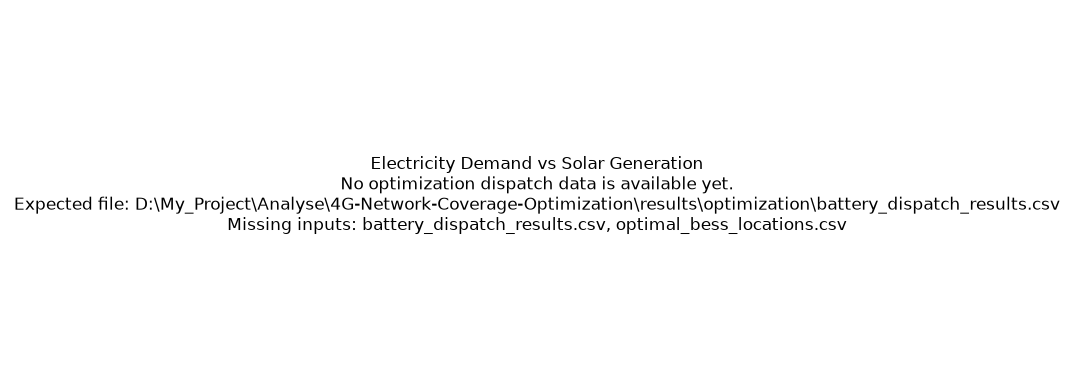

In [9]:
plot_dispatch(["demand_mw", "solar_mw"], "Electricity Demand vs Solar Generation", "Power (MW)", "solar_vs_demand.png")

### Battery charging and discharging

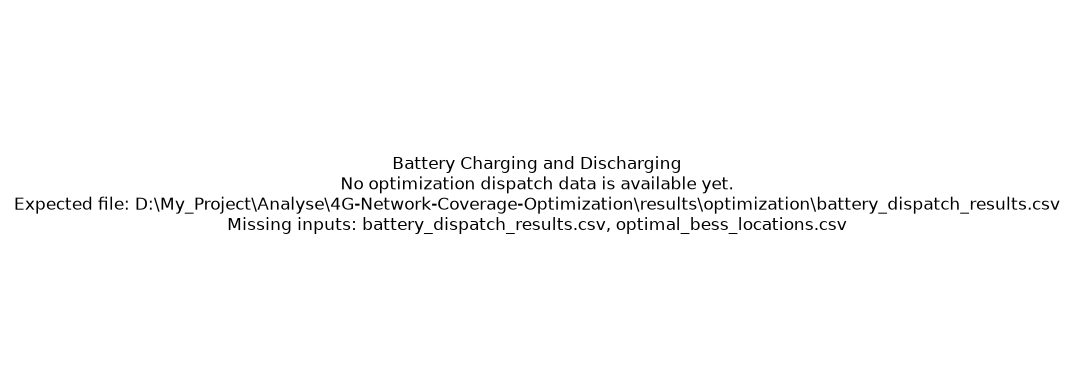

In [10]:
plot_dispatch(["battery_charge_mw", "battery_discharge_mw"], "Battery Charging and Discharging", "Power (MW)", "battery_charge_discharge.png")

### Solar curtailment

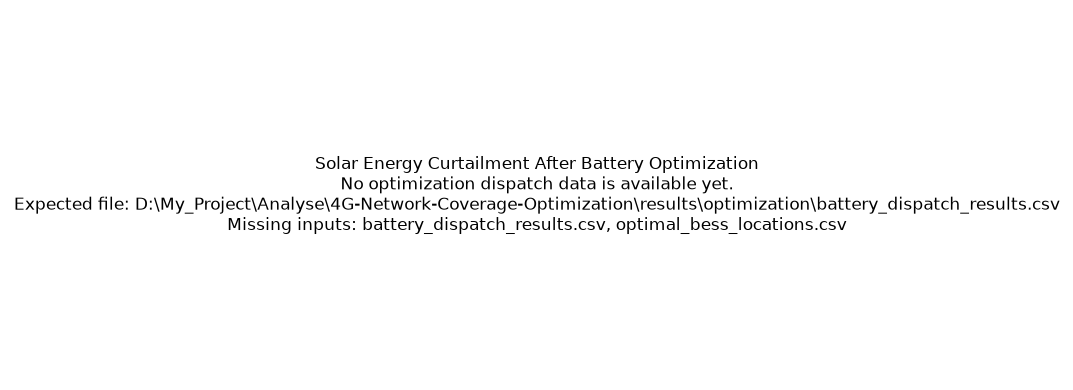

In [11]:
plot_dispatch(["solar_curtailment_mw"], "Solar Energy Curtailment After Battery Optimization", "Curtailment (MW)", "solar_curtailment.png")

### Optimal battery sizing

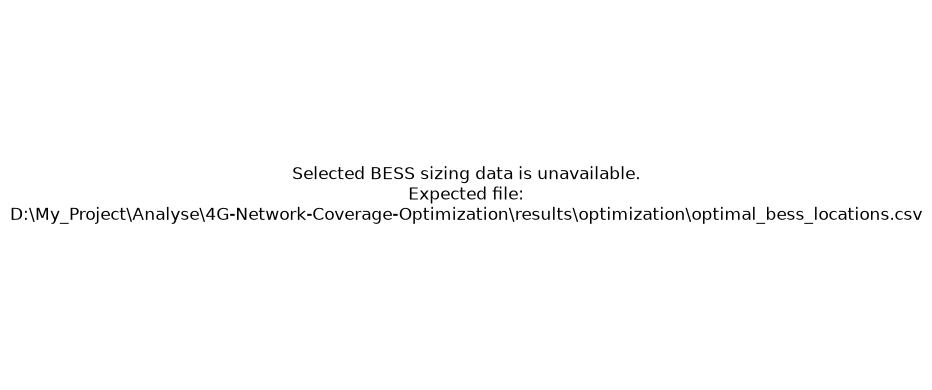

In [12]:
if not selected.empty and {"bus_id", "power_mw", "energy_mwh"}.issubset(selected.columns):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5)
    )

    axes[0].bar(
        selected["bus_id"].astype(str),
        selected["power_mw"]
    )

    axes[0].set_title("Optimal BESS Power Capacity")
    axes[0].set_ylabel("MW")
    axes[0].grid(axis="y", alpha=0.3)
    for container in axes[0].containers:
        axes[0].bar_label(container, fmt="%.1f")

    axes[1].bar(
        selected["bus_id"].astype(str),
        selected["energy_mwh"]
    )

    axes[1].set_title("Optimal BESS Energy Capacity")
    axes[1].set_ylabel("MWh")
    axes[1].grid(axis="y", alpha=0.3)
    for container in axes[1].containers:
        axes[1].bar_label(container, fmt="%.1f")

    plt.tight_layout()

    plt.savefig(
        GRAPHS / "optimal_bess_sizing.png",
        dpi=300
    )

    plt.show()
else:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.axis("off")
    detail = f"Selected BESS sizing data is unavailable.\nExpected file: {selected_path}"
    ax.text(0.5, 0.5, detail, ha="center", va="center", fontsize=12, wrap=True)
    fig.tight_layout()
    fig.savefig(GRAPHS / "optimal_bess_sizing.png", dpi=300)
    plt.show()

### Map of optimal battery sites

Substation coordinates are unavailable: D:\My_Project\Analyse\4G-Network-Coverage-Optimization\datasets\raw\gis\grid_substations.csv
No selected battery locations with coordinates are available to map.


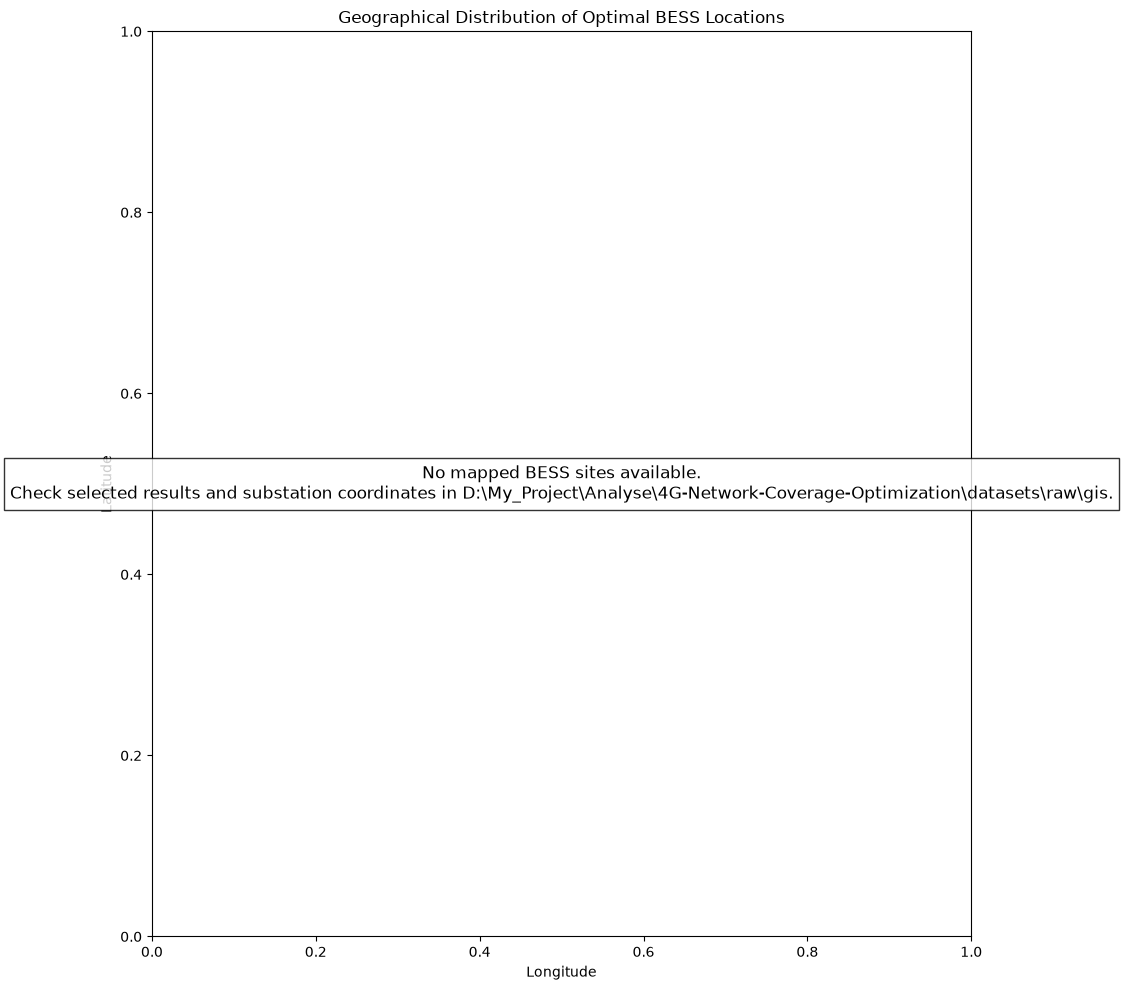

In [13]:
substations_path = GIS / "grid_substations.csv"
if substations_path.is_file():
    substations = pd.read_csv(substations_path)
else:
    print(f"Substation coordinates are unavailable: {substations_path}")
    substations = pd.DataFrame(columns=["bus_id", "longitude", "latitude"])

if "bus_id" in substations.columns and "bus_id" in selected.columns:
    substations["bus_id"] = substations["bus_id"].astype(str)
    selected["bus_id"] = selected["bus_id"].astype(str)
    map_data = substations.merge(selected, on="bus_id", how="inner")
else:
    map_data = pd.DataFrame()

fig, ax = plt.subplots(figsize=(11, 10))
boundary_path = ROOT / "datasets/raw/gis/sri_lanka_boundaries.geojson"
if boundary_path.is_file():
    import geopandas as gpd
    gpd.read_file(boundary_path).plot(ax=ax, color="white", edgecolor="black")
if {"longitude", "latitude"}.issubset(substations.columns) and not substations.empty:
    ax.scatter(substations["longitude"], substations["latitude"], color="grey", s=12, label="Grid substations")
if not map_data.empty and {"longitude", "latitude", "power_mw"}.issubset(map_data.columns):
    scatter = ax.scatter(map_data["longitude"], map_data["latitude"], c=map_data["power_mw"], s=map_data["power_mw"] * 8 + 30, cmap="viridis", edgecolors="black", label="Selected BESS sites")
    plt.colorbar(scatter, ax=ax, label="Battery Power (MW)")
else:
    print("No selected battery locations with coordinates are available to map.")
    ax.text(0.5, 0.5, f"No mapped BESS sites available.\nCheck selected results and substation coordinates in {GIS}.", transform=ax.transAxes, ha="center", va="center", fontsize=12, bbox={"facecolor": "white", "alpha": 0.8})
ax.set_title("Geographical Distribution of Optimal BESS Locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
if ax.get_legend_handles_labels()[0]:
    ax.legend()
plt.tight_layout()
plt.savefig(MAPS / "optimal_bess_location_map.png", dpi=300)
plt.show()